# Detecting DGA Domains with Machine Learning

**Goal:** teach a model to tell **normal domains** (like `googlemail.com`) from **DGA domains** (random-looking names malware generates to reach its C2 server, like `xk7qpz2mfa.net`).

**How to use this notebook**
- Run the cells **top to bottom**, one at a time, with **Shift + Enter**.
- Read the short note above each cell first — it says what the cell does and what you should see.
- If something breaks, go to *Kernel → Restart Kernel and Run All Cells*.

**The plan (same 3-step scikit-learn pattern from the slides):**
1. Get data → 2. Build features → 3. Split train/test → 4. Train models → 5. Measure → 6. Tune → 7. Save & use

## Step 0 — Install libraries (run once)
If you've already installed these, this finishes in a few seconds. You can skip it next time.

In [2]:
%pip install -q pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


## Step 1 — Import the tools
Think of `import` as "take this tool out of the toolbox so I can use it". Nothing visible happens — no output means success.

In [3]:
import math                      # for the entropy calculation
import random                    # to create sample data
from collections import Counter  # counts letters in a string

import numpy as np               # number crunching
import pandas as pd              # tables (DataFrames), like Excel in Python
import matplotlib.pyplot as plt  # charts

# scikit-learn: the machine learning library
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, make_scorer)
import joblib                    # to save/load a trained model

random.seed(42)    # makes the "random" data the same every time you run it
np.random.seed(42)
print("All libraries loaded ✅")

All libraries loaded ✅


## Step 2 — Get the data

**If your instructor gave you a CSV** (e.g. a DGA dataset), set `CSV_PATH` to its file name. It needs a column with the domain name and a column with the label.

**If not**, leave `CSV_PATH = None` and the notebook builds a realistic **sample dataset** for you, so everything below still runs.

Each row = one domain. `label` is the analyst's verdict: **0 = normal**, **1 = DGA (malicious)**. `age_days` is how long ago the domain was registered (WHOIS age) — in the slides this was the strongest feature ("DurationCreated").

In [4]:
CSV_PATH = None        # e.g. "dga_data.csv"  ← change this if you have a real file

def make_sample_data(n_each=1500):
    """Create sample normal and DGA domains with a registration age."""
    words = ["mail", "cloud", "shop", "bank", "news", "secure", "online", "data",
             "travel", "health", "home", "tech", "media", "store", "books", "india",
             "food", "music", "photo", "game", "learn", "my", "get", "app", "web",
             "portal", "smart", "global", "city", "green", "blue", "star", "live"]
    tlds = [".com", ".net", ".org", ".in", ".io", ".co"]

    rows = []
    # Normal domains: built from real words, usually registered years ago
    for _ in range(n_each):
        name = "".join(random.sample(words, random.choice([1, 2, 2, 3])))
        if random.random() < 0.15:
            name += str(random.randint(1, 99))          # some real sites have digits
        age = int(np.random.gamma(2.0, 900))             # mostly 1–8 years old
        if random.random() < 0.08:
            age = random.randint(1, 60)                  # some brand-new legit sites
        rows.append([name + random.choice(tlds), age, 0])

    # DGA domains: random letters/digits, usually registered days ago
    letters = "abcdefghijklmnopqrstuvwxyz"
    for _ in range(n_each):
        length = random.randint(8, 24)
        pool = letters + "0123456789" if random.random() < 0.6 else letters
        name = "".join(random.choice(pool) for _ in range(length))
        age = random.randint(0, 45)                      # freshly registered
        if random.random() < 0.08:
            age = random.randint(100, 2000)              # some aged/parked domains
        rows.append([name + random.choice(tlds), age, 1])

    return pd.DataFrame(rows, columns=["domain", "age_days", "label"])

if CSV_PATH:
    df = pd.read_csv(CSV_PATH)
else:
    df = make_sample_data()

df = df.sample(frac=1, random_state=42).reset_index(drop=True)   # shuffle rows
print("Rows:", len(df))
print(df["label"].value_counts().rename({0: "normal (0)", 1: "DGA (1)"}))
df.head(10)

Rows: 3000
label
DGA (1)       1500
normal (0)    1500
Name: count, dtype: int64


,domain,age_days,label
0,qnfqpezbgctljdtnmmjl.net,1,1
1,live.co,1710,0
2,410h9tn4cxkzmwedcq.in,24,1
3,media.com,1208,0
4,xiskspkechlugcpklvzwktu.co,10,1
5,webglobal.com,200,0
6,webglobal.com,2840,0
7,gqqkynrdycshtp.org,1976,1
8,webmailstore.com,951,0
9,6ccgcfs0gdnj56769g8nc.in,17,1


## Step 3 — Build features

A model can't read a domain name directly. We turn each domain into **numbers that describe it** — just like an analyst would eyeball it:

| Feature | What it measures | Why it helps |
|---|---|---|
| `length` | number of characters | DGA names are often long |
| `entropy` | how random the letters look | random strings score high |
| `digit_count` | how many digits | DGAs mix in digits |
| `vowel_ratio` | share of vowels | real words have plenty of vowels |
| `age_days` | registration age | malware domains are brand new |

In [5]:
def entropy(text):
    """Shannon entropy: higher = more random-looking."""
    counts = Counter(text)
    total = len(text)
    return -sum((c / total) * math.log2(c / total) for c in counts.values())

def build_features(domain):
    name = domain.split(".")[0].lower()   # drop the TLD: "abc.com" -> "abc"
    return {
        "length": len(name),
        "entropy": round(entropy(name), 3),
        "digit_count": sum(ch.isdigit() for ch in name),
        "vowel_ratio": round(sum(ch in "aeiou" for ch in name) / len(name), 3),
    }

features = pd.DataFrame(df["domain"].apply(build_features).tolist())
df = pd.concat([df, features], axis=1)

FEATURE_COLS = ["length", "entropy", "digit_count", "vowel_ratio", "age_days"]
df[["domain"] + FEATURE_COLS + ["label"]].head(10)

,domain,length,entropy,digit_count,vowel_ratio,age_days,label
0,qnfqpezbgctljdtnmmjl.net,20,3.722,0,0.050,1,1
1,live.co,4,2.000,0,0.500,1710,0
2,410h9tn4cxkzmwedcq.in,18,3.948,5,0.056,24,1
3,media.com,5,2.322,0,0.600,1208,0
4,xiskspkechlugcpklvzwktu.co,23,3.741,0,0.174,10,1
5,webglobal.com,9,2.725,0,0.333,200,0
6,webglobal.com,9,2.725,0,0.333,2840,0
7,gqqkynrdycshtp.org,14,3.522,0,0.000,1976,1
8,webmailstore.com,12,3.418,0,0.417,951,0
9,6ccgcfs0gdnj56769g8nc.in,21,3.463,8,0.000,17,1


**Quick sanity check:** average of each feature for normal vs DGA. You should see DGA domains are longer, more random, have more digits, fewer vowels, and are much younger.

In [6]:
df.groupby("label")[FEATURE_COLS].mean().rename(index={0: "normal", 1: "DGA"}).round(2)

,length,entropy,digit_count,vowel_ratio,age_days
label,,,,,
normal,9.39,2.74,0.26,0.38,1667.49
DGA,16.09,3.48,2.59,0.16,92.37


## Step 4 — Split into training and test sets

- `X` = the features (the evidence). `y` = the label (the verdict).
- We hide 25% of the data as a **test set** the model never sees during training — like testing an analyst on cases they haven't studied.
- `stratify=y` keeps the same normal/DGA mix in both sets.

In [7]:
X = df[FEATURE_COLS]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

print("Training rows:", len(X_train))
print("Test rows:    ", len(X_test))

Training rows: 2250
Test rows:     750


## Step 5 — Train a Random Forest (the 3-step pattern)

```
clf = RandomForestClassifier()   # 1. create
clf.fit(X_train, y_train)        # 2. train
clf.predict(X_test)              # 3. predict
```

In [8]:
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4), " ← of the alerts raised, how many were real DGA?")
print("Recall   :", round(recall_score(y_test, y_pred), 4), " ← of the real DGA domains, how many did we catch?")

Accuracy : 0.9667
Precision: 0.9581  ← of the alerts raised, how many were real DGA?
Recall   : 0.976  ← of the real DGA domains, how many did we catch?


## Step 6 — Confusion matrix (the SOC view)

- **Top-right = false positives** → normal domains we wrongly flagged (alert fatigue).
- **Bottom-left = false negatives** → DGA domains we missed (the dangerous one).

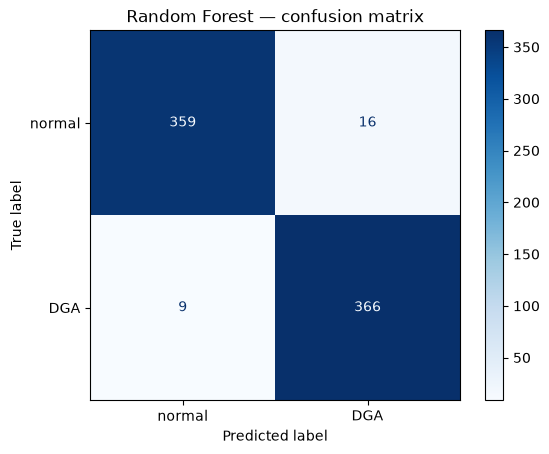

False positives: 16  |  False negatives (missed DGA): 9

              precision    recall  f1-score   support

      normal       0.98      0.96      0.97       375
         DGA       0.96      0.98      0.97       375

    accuracy                           0.97       750
   macro avg       0.97      0.97      0.97       750
weighted avg       0.97      0.97      0.97       750



In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["normal", "DGA"], cmap="Blues")
plt.title("Random Forest — confusion matrix")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"False positives: {fp}  |  False negatives (missed DGA): {fn}")
print()
print(classification_report(y_test, y_pred, target_names=["normal", "DGA"]))

## Step 7 — Which features mattered most?

Random Forest can tell us how much each feature contributed. In the slides, domain age dominated — check whether you see the same.

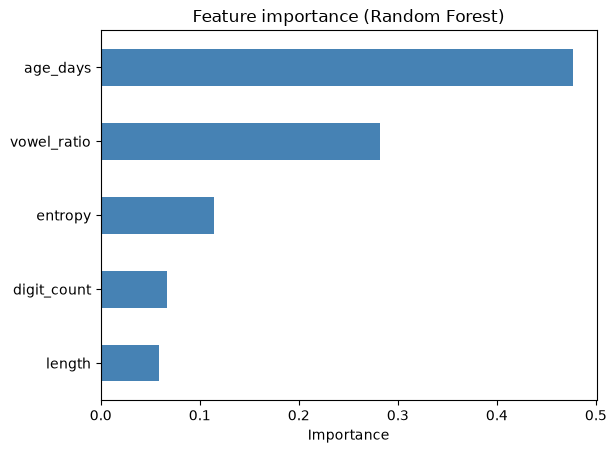

age_days       0.477
vowel_ratio    0.282
entropy        0.115
digit_count    0.067
length         0.059
dtype: float64

In [10]:
importance = pd.Series(clf.feature_importances_, index=FEATURE_COLS).sort_values()
importance.plot(kind="barh", color="steelblue")
plt.title("Feature importance (Random Forest)")
plt.xlabel("Importance")
plt.show()
importance.sort_values(ascending=False).round(3)

## Step 8 — Compare the four algorithms from the slides

Same data, same 3-step pattern, only the model changes. SVM and KNN need **scaled** features (all numbers on a similar range), so we wrap them with `StandardScaler` in a **pipeline**.

In [11]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN (k=5)":     make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "SVM":           make_pipeline(StandardScaler(), SVC()),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "false_positives": confusion_matrix(y_test, pred)[0, 1],
        "missed_DGA": confusion_matrix(y_test, pred)[1, 0],
    })

pd.DataFrame(results).set_index("model").round(4)

,accuracy,precision,recall,false_positives,missed_DGA
model,,,,,
Decision Tree,0.9667,0.9630,0.9707,14,11
KNN (k=5),0.9747,0.9890,0.9600,4,15
SVM,0.9707,0.9783,0.9627,8,14
Random Forest,0.9667,0.9581,0.9760,16,9


## Step 9 — Cross-validation (don't trust a single test)

One train/test split can be lucky. **5-fold cross-validation** trains and tests 5 times on different slices and averages the score. A small spread (±) means the model is stable.

In [12]:
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=5, scoring="f1")
    print(f"{name:14s}  F1 = {scores.mean():.4f}  (± {scores.std():.4f})")

Decision Tree   F1 = 0.9612  (± 0.0045)
KNN (k=5)       F1 = 0.9594  (± 0.0041)
SVM             F1 = 0.9590  (± 0.0039)
Random Forest   F1 = 0.9663  (± 0.0028)


## Step 10 — Tune the Random Forest with GridSearchCV

We try a few settings and keep the best. The scorer is the one from the slides: **the minimum of precision and recall**, so the model has to be good at both (few false alarms *and* few misses). This takes ~30 seconds.

In [13]:
def min_precision_recall(y_true, y_pred):
    return min(precision_score(y_true, y_pred), recall_score(y_true, y_pred))

scorer = make_scorer(min_precision_recall)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 5, 10],
    "max_features": ["sqrt", "log2"],     # note: 'auto' from the slides no longer works
}

grid = GridSearchCV(RandomForestClassifier(random_state=42),
                    param_grid, scoring=scorer, cv=5, n_jobs=-1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV score (min of precision & recall):", round(grid.best_score_, 4))

best_model = grid.best_estimator_
best_pred = best_model.predict(X_test)
print("Test precision:", round(precision_score(y_test, best_pred), 4))
print("Test recall:   ", round(recall_score(y_test, best_pred), 4))

Best settings: {'max_depth': 10, 'max_features': 'sqrt', 'n_estimators': 100}
Best CV score (min of precision & recall): 0.9579
Test precision: 0.9634
Test recall:    0.9813


## Step 11 — Save the model and use it on new domains

We save with `joblib` (the slides' `pickle.dump(clf, 'file.pkl')` line is wrong and will error). Then we load it back and score domains you type in — this is what a `/predict` API would do behind the scenes.

Notice `freshstartup.io`: a real-looking word, but only 20 days old — the model will likely flag it. That's a **false positive** driven by the age feature, exactly the trade-off you'd tune for in a SOC.

👉 **Try it:** add your own domains to the list. For a real domain you'd look up its WHOIS age; here, enter a rough guess in days.

In [14]:
joblib.dump(best_model, "dga_model.joblib")
print("Model saved to dga_model.joblib")

loaded = joblib.load("dga_model.joblib")

new_domains = [
    ("onlinebanking.com", 3650),   # (domain, registration age in days)
    ("mycloudstore.in", 1200),
    ("qx7vbz9kpl2wd.net", 3),
    ("hjgtrewqpoiuy.org", 10),
    ("freshstartup.io", 20),
]

check = pd.DataFrame([{**build_features(d), "age_days": a, "domain": d} for d, a in new_domains])
check["verdict"] = loaded.predict(check[FEATURE_COLS])
check["DGA_probability"] = loaded.predict_proba(check[FEATURE_COLS])[:, 1].round(3)
check["verdict"] = check["verdict"].map({0: "normal", 1: "⚠️ DGA"})
check[["domain", "age_days", "verdict", "DGA_probability"]]

Model saved to dga_model.joblib


,domain,age_days,verdict,DGA_probability
0,onlinebanking.com,3650,normal,0.001
1,mycloudstore.in,1200,normal,0.046
2,qx7vbz9kpl2wd.net,3,⚠️ DGA,1.000
3,hjgtrewqpoiuy.org,10,⚠️ DGA,0.876
4,freshstartup.io,20,⚠️ DGA,0.981


## What to take away

- **Accuracy alone can mislead.** Judge a detection model on **precision** (alert quality) and **recall** (coverage), and look at the false-positive count at your real traffic volume.
- **Context beats strings:** domain age usually outweighs the string features. Try removing `age_days` from `FEATURE_COLS` in Step 3 and re-run everything — watch the scores drop.
- **Always cross-validate** before trusting a number.

**Experiments to try**
1. Remove `age_days` from `FEATURE_COLS` and re-run from Step 3.
2. Change `n_neighbors` in KNN to 1, 15, 51 — what happens?
3. Set `max_depth=2` on the Decision Tree — does it underfit?